Install the following python packages using your package manager of choice (pip in this case)

In [ ]:
!pip install numpy==2.1
!pip install matplotlib
!pip install scipy
!pip install pandas
!pip install numba
!pip install plotly
!pip install bokeh
!pip install astropy
!pip install line_profiler
!pip install tqdm
!pip install ipyformkit==0.3.5
!pip install lxml
!pip install parse
!pip install pyinstrument

Import the `m3dis` python package amongst other common packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tumult
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OMP_STACKSIZE'] = '256M'
plt.style.use('tumult/Bergemann2020.mplstyle')
#plt.style.use('tumult/Bergemann2023.mplstyle') # uncomment for serif axis labels
%config InlineBackend.figure_format='svg' # turns plots into vector graphics inside this notebook

Execute Multi by calling the Dispatch executable and supplying the default demo input parameter file `demo.nml`.
This will run a 1D solar Marcs model using a 6-Level toy Barium atom.

In [3]:
! ./dispatch.x demo.nml

OMP: Warning #182: OMP_STACKSIZE: ignored because KMP_STACKSIZE has been defined
 This version was compiled with default real KIND = 4
 MPI is not enabled!
 DISPATCH code framework, branch:tumult, hash:eddc0e96a
 SOLVER=None OPTS=
 Intel(R) Version 2021.11.1 Build 20231117_000000  
 ================================ mpi_t%info ====================================
 n_sockets =   1
   n_cores =  36
 n_threads =   1
  n_places =  72
   n_ranks =   1
 Stacksize =   256MB
 This version was compiled with default real KIND = 4
 ================================= io_t%init ====================================
 parameters from: demo.nml
 output directory: data/demo/
 ============================ read_external_t%ini ===============================
FeH was overwritten by Marcs model: [Fe/H] =  0.00
Vmic was overwritten by Marcs model: Vmic =  1.00
 ME I  deactivated!
  - Reading atom ./input_multi3d/atoms/atom.ba06 F
  - Reading collision data
Changing abundance of Ba from  2.17 to  2.11
sp_from_at

The default output directory is `./data/`. A new subfolder is created according to the name of your input parameter file. It can be opened and read as follows:

In [2]:
run = tumult.read('data/demo/')

Now we have created an object with the name of `run`. This object contains all of the data and meta-data of our demo run. The spectral data is contained in run.spectrum. This is a Spectrum object, which is essentially a pandas DataFrame with some additional methods for easy plotting and data manipulation. It contains the wavelength in Angstroms and three sets of spectra (NLTE, LTE, cont). Each set then contains spectra for the various mu-angles in the angle quadrature as well as the flux.

In [3]:
run.spectrum

Å             NLTE              LTE             Cont  \
                             Flux             Flux             Flux   
                                                                      
                 erg Å⁻¹ s⁻¹ cm⁻² erg Å⁻¹ s⁻¹ cm⁻² erg Å⁻¹ s⁻¹ cm⁻²   
0    4552.818181     1.108184e+07     1.108149e+07     1.114257e+07   
1    4552.830327     1.108060e+07     1.108023e+07     1.114255e+07   
2    4552.842473     1.107931e+07     1.107894e+07     1.114253e+07   
3    4552.854619     1.107799e+07     1.107761e+07     1.114251e+07   
4    4552.866766     1.107662e+07     1.107624e+07     1.114249e+07   
..           ...              ...              ...              ...   
799  6497.522157     7.506657e+06     7.506966e+06     7.532145e+06   
800  6497.528660     7.507167e+06     7.507473e+06     7.532133e+06   
801  6497.535163     7.507660e+06     7.507962e+06     7.532120e+06   
802  6497.541665     7.508141e+06     7.508435e+06     7.532109e+06   
803  6497.548168     7.508605e+06     7.508892e+06     7.532098e+06   

                     NLTE                                              \
                   µ=1.00                µ=0.87                µ=0.59   
                        0                     1                     2   
    erg Å⁻¹ s⁻¹ sr⁻¹ cm⁻² erg Å⁻¹ s⁻¹ sr⁻¹ cm⁻² erg Å⁻¹ s⁻¹ sr⁻¹ cm⁻²   
0            4.718603e+06          4.285043e+06          3.261333e+06   
1            4.718129e+06          4.284584e+06          3.260938e+06   
2            4.717636e+06          4.284111e+06          3.260532e+06   
3            4.717133e+06          4.283626e+06          3.260115e+06   
4            4.716613e+06          4.283123e+06          3.259681e+06   
..                    ...                   ...                   ...   
799          2.909964e+06          2.721040e+06          2.269551e+06   
800          2.910157e+06          2.721226e+06          2.269711e+06   
801          2.910341e+06          2.721405e+06          2.269866e+06   
802          2.910521e+06          2.721579e+06          2.270018e+06   
803          2.910696e+06          2.721747e+06          2.270164e+06   

                                            LTE                        \
                   µ=0.21                µ=1.00                µ=0.87   
                        3                     0                     1   
    erg Å⁻¹ s⁻¹ sr⁻¹ cm⁻² erg Å⁻¹ s⁻¹ sr⁻¹ cm⁻² erg Å⁻¹ s⁻¹ sr⁻¹ cm⁻²   
0            1.735948e+06          4.718500e+06          4.284933e+06   
1            1.735743e+06          4.718025e+06          4.284470e+06   
2            1.735532e+06          4.717531e+06          4.283997e+06   
3            1.735315e+06          4.717024e+06          4.283507e+06   
4            1.735091e+06          4.716500e+06          4.283004e+06   
..                    ...                   ...                   ...   
799          1.539535e+06          2.910007e+06          2.721090e+06   
800          1.539627e+06          2.910197e+06          2.721276e+06   
801          1.539716e+06          2.910383e+06          2.721454e+06   
802          1.539803e+06          2.910562e+06          2.721627e+06   
803          1.539886e+06          2.910735e+06          2.721794e+06   

                                                                 Cont  \
                   µ=0.59                µ=0.21                µ=1.00   
                        2                     3                     0   
    erg Å⁻¹ s⁻¹ sr⁻¹ cm⁻² erg Å⁻¹ s⁻¹ sr⁻¹ cm⁻² erg Å⁻¹ s⁻¹ sr⁻¹ cm⁻²   
0            3.261209e+06          1.735854e+06          4.741509e+06   
1            3.260813e+06          1.735648e+06          4.741496e+06   
2            3.260403e+06          1.735436e+06          4.741484e+06   
3            3.259982e+06          1.735217e+06          4.741471e+06   
4            3.259547e+06          1.734991e+06          4.741461e+06   
..                    ...                   ...                   ...   
799          2.269631e+06  

In order to only extract flux or intensity spectra, we can use the `crop` method. Here we extract the NLTE flux spectrum only:

to plot the resulting spectrum, we can use the built-in plot method:

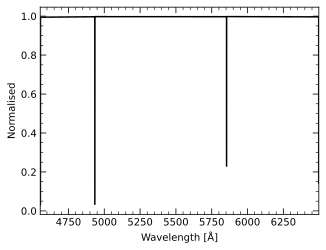

In [4]:
run.crop().plot(color='black')

To zoom into a part of the spectrum one may do:

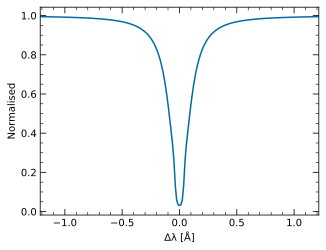

In [5]:
lam0 = 4554.033
dlam = 2.5
run.crop(lam0=lam0, dlam=dlam).plot()

We trim the underlying spectral data using the  `crop()` function of the `run` object. It has many useful arguments. Here I list the most important ones:
1. `lam0`, `dlam`: can be used in combination in order to crop the spectrum to a region around a central wavelength lam0. dlam may also be a tuple, e.g. (-0.5, 0.2), which would result in asymmetric cropping aroun lam0.
2. `xmin`,`xmax`: alternatively one may pass xmin and xmax instead to crop the wavelengths.
3. `relative=False`: when one uses lam0 and dlam, the wavelength values are given as distance from lam0, but by setting relative=False, one can keep the original wavelengths.
4. `norm=False`: plots the unnormalised spectrum.
5. `imu=0`: plots the disk-center intensity, rather than the flux. By increasing imu, you can plot the various angles of the chosen angle quadrature of the run.
6. `vdop=1.5`: applies doppler broadening with a velocity of 1.5 km/s by convolving with a Gaussian profile.
7. `vshift=1.5`: doppler shifts the spectrum corresponding to a velocity of 1.5 km/s.
8. `LTE=True`: plots the LTE spectrum. By default it will try to plot the NLTE spectrum.


An array accessible via `run.line` contains multiple objects of the `trans_class`. This class makes plotting of spectral lines stored in the model atom very easy. Each run stores both LTE and NLTE spectra by default. Let's make a quick comparison:

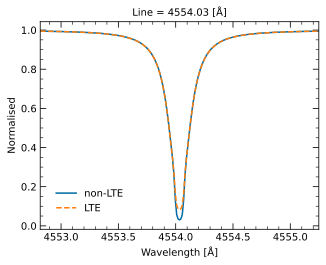

In [6]:
imu = None # None gives flux, use integers to plot intensities for different angles
norm = True # set to False for unnormalised line profile
ka = 0 # atom index
kr = 0 # line index

line = run.atoms[ka].line[kr]
line.crop(imu=imu, norm=norm, LTE=False).plot(linestyle='-', label='non-LTE')
line.crop(imu=imu, norm=norm, LTE=True).plot(linestyle='--', label='LTE')
plt.title(line.title)
plt.legend()

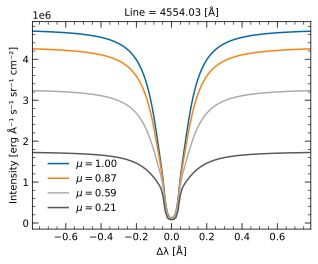

In [7]:
dlam = 0.8 # zooms into the line profile to ±dlam angstroms.
norm = False

# alternatively one may get the line object by its wavelength
line = run.get_line(4554.033)

 # iterate over all angles
for imu, mu in enumerate(run.mus):
  label = r'$\mu=${:.2f}'.format(mu)
  line.crop(imu=imu, norm=norm, dlam=dlam).plot(label=label)

plt.title(line.title)
plt.legend()

Text(0.5, 1.0, 'Line = 4554.03 [Å]')

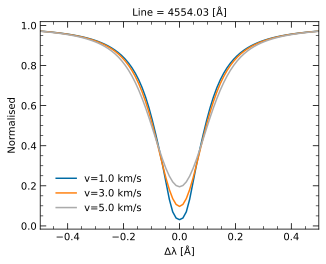

In [8]:
dlam = 0.5
imu = 0
line = run.get_line(4554.033)

 # convolve with doppler profiles
for vdop in [1.0, 3.0, 5.0]:
  label = 'v={:.1f} km/s'.format(vdop)
  line.crop(imu=imu, dlam=dlam, vdop=vdop).plot(label=label)

plt.legend()
plt.title(line.title)

Here is a quick example of how to save the spectral line profile as an ascii table. In this case we decide to save the Flux as well as the individual mu-angles.

In [ ]:
line = run.get_line(4554.033)
line.prepare()
ascii_table = line.spectrum.df.to_string(index=False) # df converts the spectrum to a pandas DataFrame
print(ascii_table)

          Å             NLTE              LTE             Cont                  NLTE                                                                                     LTE                                                                                    Cont                                                                  
                        Flux             Flux             Flux                µ=1.00                µ=0.87                µ=0.59                µ=0.21                µ=1.00                µ=0.87                µ=0.59                µ=0.21                µ=1.00                µ=0.87                µ=0.59                µ=0.21
                                                                                   0                     1                     2                     3                     0                     1                     2                     3                     0                     1                     2                     3
            erg Å⁻¹

Let's download a 3D solar atmosphere snapshot from our website at nlte.mpia.de.

In [ ]:
from urllib import request
import zipfile
import os

# Define the URL and output paths
url = 'https://gemini-web.mpia.de/atmos3D/SunLTE_E_t57.77g44.40m0.000_v1.0/SunLTE_t5777_g4.440_z0.000_sn779_m3dis.zip'
out_dir = 'input_multi3d/atmos/'
tmp = out_dir + 'SunLTE_m3dis.zip'

# Download the file
print("Downloading...")
request.urlretrieve(url, tmp)
print("Download complete.")

# Unzip the file
print("Unzipping...")
with zipfile.ZipFile(tmp, 'r') as zip_ref:
    zip_ref.extractall(out_dir)
print("Unzipping complete.")

# remove the zip file
os.remove(tmp)

Now we can run the 3D example. This may take a while, depending on your machine. The output will be stored in data/demo3d/.

In [ ]:
! ./dispatch.x demo3d.nml